# Consultas obligatorias — PanTEon en MongoDB

Bases de Datos II · Proyecto del segundo corte

Este notebook ejecuta las 15 consultas obligatorias de la sección 4.3 del enunciado,
la generación de bibliotecas FASTA (consultas 10 y 11) y dos preguntas de
investigación propias. Cada consulta muestra: la pregunta, el código (función de
`scripts/queries.py`), el resultado y su interpretación.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../scripts"))
import json
import queries as q
import generate_libraries as lib

def show(data, limit=10):
    if isinstance(data, list):
        print(json.dumps(data[:limit], indent=2, default=str))
        if len(data) > limit:
            print(f"... ({len(data)} filas totales, se muestran {limit})")
    else:
        print(json.dumps(data, indent=2, default=str))

## Cantidad de elementos

### Consulta 1
**¿Cuántos TEs hay por clase, por orden y por superfamilia en toda la base?**

In [2]:
r1 = q.q1_count_by_classification()
print("--- Por clase ---"); show(r1["por_clase"])
print("--- Por orden ---"); show(r1["por_orden"])
print("--- Por superfamilia (top 10) ---"); show(r1["por_superfamilia"], 10)

--- Por clase ---
[
  {
    "_id": "CLASSI",
    "n": 194774
  },
  {
    "_id": "CLASSII",
    "n": 45172
  }
]
--- Por orden ---
[
  {
    "_id": "LTR",
    "n": 119368
  },
  {
    "_id": "LINE",
    "n": 68382
  },
  {
    "_id": "TIR",
    "n": 36471
  },
  {
    "_id": "HELITRON",
    "n": 5075
  },
  {
    "_id": "SINE",
    "n": 3634
  },
  {
    "_id": "MITE",
    "n": 3456
  },
  {
    "_id": "DIRS",
    "n": 2933
  },
  {
    "_id": "PLE",
    "n": 344
  },
  {
    "_id": "RETROPOSON",
    "n": 113
  },
  {
    "_id": "CRYPTON",
    "n": 112
  }
]
... (11 filas totales, se muestran 10)
--- Por superfamilia (top 10) ---
[
  {
    "_id": "COPIA",
    "n": 50849
  },
  {
    "_id": "GYPSY",
    "n": 43963
  },
  {
    "_id": "L1",
    "n": 23821
  },
  {
    "_id": "ERV",
    "n": 12202
  },
  {
    "_id": "CR1",
    "n": 11234
  },
  {
    "_id": "L2",
    "n": 10962
  },
  {
    "_id": "TC1MARINER",
    "n": 10729
  },
  {
    "_id": "HAT",
    "n": 10648
  },
  {
    "_id": 

**Interpretación:** CLASSI (retrotransposones) domina ampliamente con 194,774
TEs (81.2%) frente a CLASSII (DNA transposones) con 45,172 (18.8%). Entre los
órdenes, LTR es el más abundante (119,368), seguido de LINE (68,382) y TIR
(36,471) — consistente con que LTR y LINE son retrotransposones, el mecanismo de
replicación "copiar y pegar" que tiende a generar más copias que los elementos de
clase II.

### Consulta 2
**¿Cuántos TEs tiene cada especie, desglosados por clase, orden y superfamilia?**
(Ejemplo con una especie; la función acepta `species_name=None` para toda la base.)

In [3]:
r2 = q.q2_count_by_species("Halicephalobus mephisto")
show(r2)

[
  {
    "_id": {
      "species": "Halicephalobus mephisto",
      "te_class": "CLASSII",
      "te_order": "TIR",
      "te_superfamily": "TC1MARINER"
    },
    "n": 7
  },
  {
    "_id": {
      "species": "Halicephalobus mephisto",
      "te_class": "CLASSII",
      "te_order": "HELITRON",
      "te_superfamily": "HELITRON"
    },
    "n": 2
  },
  {
    "_id": {
      "species": "Halicephalobus mephisto",
      "te_class": "CLASSI",
      "te_order": "LINE",
      "te_superfamily": "RTE"
    },
    "n": 1
  }
]


**Interpretación:** *Halicephalobus mephisto* tiene solo 10 TEs en la base,
repartidos en 3 combinaciones clase/orden/superfamilia distintas — una biblioteca
pequeña, típica de las especies con pocos TEs anotados (ver consulta 4).

### Consulta 3
**¿Cómo cambia la cantidad de TEs por clase y orden entre reinos? ¿Y entre phyla?**

In [4]:
r3 = q.q3_counts_by_kingdom_and_phylum()
print("--- Por reino (primeras filas) ---"); show(r3["por_reino"], 10)

--- Por reino (primeras filas) ---
[
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSI",
      "te_order": "LINE"
    },
    "n": 44477
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSI",
      "te_order": "LTR"
    },
    "n": 25382
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSII",
      "te_order": "TIR"
    },
    "n": 21659
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSI",
      "te_order": "SINE"
    },
    "n": 3091
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSII",
      "te_order": "MITE"
    },
    "n": 2718
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSI",
      "te_order": "DIRS"
    },
    "n": 2125
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSII",
      "te_order": "HELITRON"
    },
    "n": 1167
  },
  {
    "_id": {
      "kingdom": "Animalia",
      "te_class": "CLASSI",
      

**Interpretación:** en Animalia predomina LINE (44,477) sobre LTR (25,382);
en cambio Plantae y Fungi están dominados por LTR (ver consulta 1 y 6 para más
contexto) — refleja diferencias evolutivas conocidas en el "transposon landscape"
entre reinos: los retrotransposones LINE son más activos en genomas animales,
mientras que las plantas acumulan masivamente elementos LTR (particularmente
Gypsy y Copia).

### Consulta 4
**¿Cuáles son las 10 especies con más TEs y las 10 con menos?**

In [5]:
r4 = q.q4_top_bottom_species()
print("--- Top 10 ---"); show(r4["top"])
print("--- Bottom 10 ---"); show(r4["bottom"])

--- Top 10 ---
[
  {
    "_id": "Malus domestica",
    "n": 1627
  },
  {
    "_id": "Danio rerio",
    "n": 1352
  },
  {
    "_id": "Callithrix jacchus",
    "n": 1294
  },
  {
    "_id": "Homininae",
    "n": 1173
  },
  {
    "_id": "Nicotiana attenuata",
    "n": 1159
  },
  {
    "_id": "Colobus angolensis",
    "n": 1148
  },
  {
    "_id": "Chlorocebus sabaeus",
    "n": 1129
  },
  {
    "_id": "Geotrypetes seraphini",
    "n": 1115
  },
  {
    "_id": "Sitophilus oryzae",
    "n": 1103
  },
  {
    "_id": "Oryza sativa",
    "n": 1090
  }
]
--- Bottom 10 ---
[
  {
    "_id": "Alternaria incomplexa",
    "n": 1
  },
  {
    "_id": "Phycomyces nitens",
    "n": 1
  },
  {
    "_id": "Xylaria multiplex",
    "n": 1
  },
  {
    "_id": "Verticillium alfalfae",
    "n": 1
  },
  {
    "_id": "Gnomoniopsis castaneae",
    "n": 1
  },
  {
    "_id": "Ogataea haglerorum",
    "n": 1
  },
  {
    "_id": "Xylaria bambusicola",
    "n": 1
  },
  {
    "_id": "Dacrymyces fennicus",
    "

**Interpretación:** *Malus domestica* (manzano) encabeza con 1627 TEs, seguida
de *Danio rerio* (pez cebra) con 1352. Las especies "bottom" tienen exactamente 1
TE cada una — probablemente genomas con bibliotecas de TEs apenas iniciadas o
especies con anotación preliminar, más que genomas realmente pobres en TEs.

## Longitud y contenido GC

### Consulta 5
**¿Cuál es la longitud promedio, mínima y máxima de los TEs por clase, orden y
superfamilia?**

In [6]:
r5 = q.q5_length_stats_by_classification()
print("--- Por clase ---"); show(r5["por_clase"])
print("--- Por orden ---"); show(r5["por_orden"])

--- Por clase ---
[
  {
    "_id": "CLASSI",
    "avg_length": 4453.147499152864,
    "min_length": 81,
    "max_length": 19926,
    "n": 194774
  },
  {
    "_id": "CLASSII",
    "avg_length": 2137.2545824847252,
    "min_length": 100,
    "max_length": 18485,
    "n": 45172
  }
]
--- Por orden ---
[
  {
    "_id": "CRYPTON",
    "avg_length": 303.42857142857144,
    "min_length": 108,
    "max_length": 2367,
    "n": 112
  },
  {
    "_id": "DIRS",
    "avg_length": 4413.54210705762,
    "min_length": 109,
    "max_length": 6998,
    "n": 2933
  },
  {
    "_id": "HELITRON",
    "avg_length": 4094.5867980295566,
    "min_length": 100,
    "max_length": 14819,
    "n": 5075
  },
  {
    "_id": "LINE",
    "avg_length": 3241.435801819192,
    "min_length": 500,
    "max_length": 6000,
    "n": 68382
  },
  {
    "_id": "LTR",
    "avg_length": 5285.582107432478,
    "min_length": 100,
    "max_length": 19926,
    "n": 119368
  },
  {
    "_id": "MAVERICK",
    "avg_length": 6395.482758

**Interpretación:** CLASSI es en promedio más del doble de largo que CLASSII
(4453 nt vs. 2137 nt) — coherente con que los retrotransposones LTR completos
incluyen genes de poliproteína (gag/pol) además de las repeticiones terminales,
mientras que muchos elementos de clase II son transposones más compactos.

### Consulta 6
**¿Cuál es el porcentaje de GC promedio por orden y por reino?**

In [7]:
r6 = q.q6_gc_by_order_and_kingdom()
print("--- Por orden ---"); show(r6["por_orden"])
print("--- Por reino ---"); show(r6["por_reino"])

--- Por orden ---
[
  {
    "_id": "CRYPTON",
    "avg_gc": 45.158410714285715,
    "n": 112
  },
  {
    "_id": "DIRS",
    "avg_gc": 52.595347596317765,
    "n": 2933
  },
  {
    "_id": "HELITRON",
    "avg_gc": 41.03805341871921,
    "n": 5075
  },
  {
    "_id": "LINE",
    "avg_gc": 43.808999742622326,
    "n": 68382
  },
  {
    "_id": "LTR",
    "avg_gc": 42.81327303213592,
    "n": 119368
  },
  {
    "_id": "MAVERICK",
    "avg_gc": 40.15147068965517,
    "n": 58
  },
  {
    "_id": "MITE",
    "avg_gc": 41.47327346643519,
    "n": 3456
  },
  {
    "_id": "PLE",
    "avg_gc": 44.42865988372093,
    "n": 344
  },
  {
    "_id": "RETROPOSON",
    "avg_gc": 50.68937256637168,
    "n": 113
  },
  {
    "_id": "SINE",
    "avg_gc": 52.972363291139246,
    "n": 3634
  }
]
... (11 filas totales, se muestran 10)
--- Por reino ---
[
  {
    "_id": "Animalia",
    "avg_gc": 44.47864179783279,
    "n": 101144
  },
  {
    "_id": "Fungi",
    "avg_gc": 46.17283331817952,
    "n": 19797


**Interpretación:** SINE y DIRS tienen el GC% más alto (~53%), mientras que
TIR y MAVERICK rondan el 40%. Entre reinos, Fungi tiene el GC% más alto (46.2%) y
Plantae el más bajo (41.2%), lo que es consistente con la composición de base
general de esos genomas (los genomas fúngicos suelen tener GC% más alto que los
de muchas plantas).

### Consulta 7
**¿Qué TEs son los más largos y los más cortos de cada reino?**

In [8]:
r7 = q.q7_longest_shortest_by_kingdom()
show(r7)

{
  "Animalia": {
    "mas_largo": {
      "original_id": "PDB00076912",
      "te_class": "CLASSI",
      "te_order": "LTR",
      "te_superfamily": "ERV",
      "species_name": "Aphelocoma californica",
      "length": 18951
    },
    "mas_corto": {
      "original_id": "AllBul-4.608",
      "te_class": "CLASSI",
      "te_order": "SINE",
      "te_superfamily": "ID",
      "species_name": "Orientallactaga bullata",
      "length": 81
    }
  },
  "Plantae": {
    "mas_largo": {
      "original_id": "PDB00038441",
      "te_class": "CLASSI",
      "te_order": "LTR",
      "te_superfamily": "GYPSY",
      "species_name": "Helianthus annuus",
      "length": 19926
    },
    "mas_corto": {
      "original_id": "PDB00099833",
      "te_class": "CLASSI",
      "te_order": "LTR",
      "te_superfamily": "GYPSY",
      "species_name": "Arachis monticola",
      "length": 100
    }
  },
  "Fungi": {
    "mas_largo": {
      "original_id": "PDB00194372",
      "te_class": "CLASSI",
      "t

**Interpretación:** los TEs más largos en los tres reinos son elementos LTR
(ERV o GYPSY) de 18,900–19,900 nt — cerca del máximo teórico observado en toda la
base (19,926 nt). Los más cortos rondan 81–100 nt, el límite inferior fijado por
la base de datos para considerar algo un TE.

## Nombres y búsqueda de secuencias

### Consulta 8
**Buscar una secuencia por su nombre y mostrar su clasificación, especie y
taxonomía completa.**

In [9]:
r8 = q.q8_search_by_id("PDB00000001")
show(r8)

{
  "original_id": "PDB00000001",
  "te_class": "CLASSII",
  "te_order": "HELITRON",
  "te_superfamily": "HELITRON",
  "species_name": "Halicephalobus mephisto",
  "taxonomy": {
    "kingdom": "Animalia",
    "phylum": "Nematoda",
    "taxo_class": "Chromadorea",
    "taxo_order": "Rhabditida",
    "family": "Panagrolaimidae"
  }
}


**Interpretación:** confirma el ejemplo del propio enunciado — `PDB00000001`
es un HELITRON de *Halicephalobus mephisto*, con taxonomía completa
Animalia/Nematoda/Chromadorea/Rhabditida/Panagrolaimidae recuperada vía
`$lookup`.

### Consulta 9
**Listar los nombres de todas las secuencias de una superfamilia en una especie
dada.**

In [10]:
r9 = q.q9_sequence_names_by_superfamily_species("HELITRON", "Halicephalobus mephisto")
show(r9)

[
  "PDB00000001",
  "PDB00000002"
]


**Interpretación:** *Halicephalobus mephisto* tiene exactamente 2 TEs de la
superfamilia HELITRON en la base.

## Generación de bibliotecas

Construidas **a partir de una consulta a MongoDB** (no leyendo el FASTA original),
exportadas con el mismo formato de encabezado `>ID#CLASE/ORDEN/SUPERFAMILIA @Especie`.
Los archivos quedan en `data/libraries/`.

### Consulta 10 — Biblioteca de una especie

In [11]:
n = lib.library_by_species("Halicephalobus mephisto", "../data/libraries/Halicephalobus_mephisto.fasta")
print(f"{n} secuencias exportadas a data/libraries/Halicephalobus_mephisto.fasta")

10 secuencias exportadas a data/libraries/Halicephalobus_mephisto.fasta


### Consulta 11 — Biblioteca de un reino

In [12]:
n = lib.library_by_kingdom("Fungi", "../data/libraries/Fungi.fasta")
print(f"{n} secuencias exportadas a data/libraries/Fungi.fasta")

19797 secuencias exportadas a data/libraries/Fungi.fasta


**Interpretación:** ambas funciones reciben la especie o el reino como
parámetro (no están codificados a mano), por lo que la misma consulta genera la
biblioteca de cualquier especie o reino de la base.

## Relaciones y calidad

### Consulta 12
**Consulta que use `$lookup` para unir secuencias con la taxonomía de su
especie.**

In [13]:
r12 = q.q12_lookup_sequences_taxonomy(5)
show(r12)

[
  {
    "original_id": "PDB00000001",
    "te_class": "CLASSII",
    "te_order": "HELITRON",
    "te_superfamily": "HELITRON",
    "species_name": "Halicephalobus mephisto",
    "kingdom": "Animalia",
    "phylum": "Nematoda"
  },
  {
    "original_id": "PDB00000002",
    "te_class": "CLASSII",
    "te_order": "HELITRON",
    "te_superfamily": "HELITRON",
    "species_name": "Halicephalobus mephisto",
    "kingdom": "Animalia",
    "phylum": "Nematoda"
  },
  {
    "original_id": "PumCon-1.11",
    "te_class": "CLASSI",
    "te_order": "SINE",
    "te_superfamily": "TRNA",
    "species_name": "Puma concolor",
    "kingdom": "Animalia",
    "phylum": "Chordata"
  },
  {
    "original_id": "PumCon-1.141",
    "te_class": "CLASSII",
    "te_order": "TIR",
    "te_superfamily": "TC1MARINER",
    "species_name": "Puma concolor",
    "kingdom": "Animalia",
    "phylum": "Chordata"
  },
  {
    "original_id": "PumCon-1.14",
    "te_class": "CLASSI",
    "te_order": "SINE",
    "te_superfami

**Interpretación:** el `$lookup` resuelve correctamente la taxonomía (reino,
phylum) de cada secuencia a partir de su `species_id`, sin necesidad de duplicar
esos campos en cada uno de los 239,946 documentos de `sequences`.

### Consulta 13
**Comparación por origen de los datos (columna `Source`).**

In [14]:
r13 = q.q13_comparison_by_source()
show(r13)

[
  {
    "_id": "RM2+MCH",
    "n_secuencias": 208354,
    "avg_length": 4375.507492056788,
    "n_especies": 2404,
    "avg_secuencias_por_especie": 86.66971713810317
  },
  {
    "_id": "Dfam",
    "n_secuencias": 31592,
    "avg_length": 1653.8024499873386,
    "n_especies": 386,
    "avg_secuencias_por_especie": 81.84455958549223
  }
]


**Interpretación:** las bibliotecas `RM2+MCH` (generadas automáticamente)
cubren 2404 especies con 208,354 secuencias (86.7 secuencias/especie en
promedio), mientras que `Dfam` (base de referencia curada) cubre solo 386
especies pero con bibliotecas también sustanciales (81.8 secuencias/especie). La
diferencia más notable es la longitud promedio: 4375 nt en RM2+MCH vs. 1654 nt en
Dfam — probablemente porque Dfam incluye muchos fragmentos de consenso más cortos
y bibliotecas ancestrales de clado (ver `docs/data_quality_notes.md`).

### Consulta 14
**Consulta de control de calidad propia: secuencias con porcentaje de N alto
(>5%, posible indicio de ensamblaje de baja calidad en esa región del genoma).**

In [15]:
r14 = q.q14_quality_control()
show(r14)

{
  "umbral_pct_n": 5.0,
  "secuencias_sobre_umbral": 4374,
  "total_secuencias": 239946,
  "porcentaje": 1.8229,
  "ejemplos": [
    {
      "original_id": "Halyomorpha_halys-5_family-957",
      "length": 797,
      "n_percentage": 50.0627
    },
    {
      "original_id": "TC1DR1",
      "length": 505,
      "n_percentage": 45.5446
    },
    {
      "original_id": "Halyomorpha_halys-5_family-2805",
      "length": 395,
      "n_percentage": 34.1772
    },
    {
      "original_id": "BEL33_DR",
      "length": 7203,
      "n_percentage": 32.07
    },
    {
      "original_id": "fAlbLTRK1b",
      "length": 3200,
      "n_percentage": 31.4688
    },
    {
      "original_id": "TguLTR13c_fAlb",
      "length": 1591,
      "n_percentage": 30.2954
    },
    {
      "original_id": "TguLTRL1a7-b_fAlb",
      "length": 1636,
      "n_percentage": 29.4621
    },
    {
      "original_id": "Penelope-2_DR",
      "length": 3728,
      "n_percentage": 28.7285
    },
    {
      "original_id":

**Interpretación:** 4374 secuencias (1.82% del total) tienen más de 5% de
N's. Es una minoría, pero no despreciable — el pipeline las conserva (no las
descarta) y simplemente excluye los k-mers que contienen N, para no sesgar los
conteos.

## K-mers

### Consulta 15
**Recuperar el perfil de k-mers de una secuencia dada, para un k dado.**

In [16]:
r15 = q.q15_kmer_profile("PDB00000001", 2)
show(r15)

{
  "original_id": "PDB00000001",
  "k": 2,
  "profile": {
    "AA": 306,
    "AC": 74,
    "CA": 97,
    "AG": 110,
    "GA": 123,
    "CT": 102,
    "TT": 234,
    "TA": 193,
    "AT": 229,
    "TC": 103,
    "GC": 75,
    "CG": 53,
    "GG": 55,
    "TG": 113,
    "GT": 78,
    "CC": 45
  }
}


**Interpretación:** el perfil de 2-mers de `PDB00000001` tiene las 16
combinaciones posibles presentes (secuencia larga y sin N), con AA (306) y TT
(234) como los más frecuentes — refleja el alto contenido de homopolímeros A/T
típico de regiones ricas en AT de este elemento.

## Preguntas propias

### Propia 1
**¿Cuál es la superfamilia de TE más frecuente en cada reino?**

In [17]:
p1 = q.p1_dominant_superfamily_per_kingdom()
show(p1)

{
  "Animalia": {
    "te_superfamily": "ERV",
    "n": 12191
  },
  "Fungi": {
    "te_superfamily": "TAD1",
    "n": 3840
  },
  "Plantae": {
    "te_superfamily": "COPIA",
    "n": 47555
  }
}


**Interpretación:** cada reino tiene una superfamilia dominante distinta —
ERV en Animalia, TAD1 en Fungi y COPIA en Plantae — lo que confirma que la
composición de TEs no es uniforme entre reinos y que agrupar por superfamilia
(no solo por clase/orden) aporta información filogenética relevante.

### Propia 2
**¿Las superfamilias (agrupadas por orden) con más contenido GC tienden a tener
TEs más largos?**

In [18]:
p2 = q.p2_gc_length_correlation_by_order()
show(p2, 11)

[
  {
    "_id": "SINE",
    "avg_gc": 52.972363291139246,
    "avg_length": 253.3093010456797,
    "n": 3634
  },
  {
    "_id": "DIRS",
    "avg_gc": 52.595347596317765,
    "avg_length": 4413.54210705762,
    "n": 2933
  },
  {
    "_id": "RETROPOSON",
    "avg_gc": 50.68937256637168,
    "avg_length": 1290.9734513274336,
    "n": 113
  },
  {
    "_id": "CRYPTON",
    "avg_gc": 45.158410714285715,
    "avg_length": 303.42857142857144,
    "n": 112
  },
  {
    "_id": "PLE",
    "avg_gc": 44.42865988372093,
    "avg_length": 2211.6220930232557,
    "n": 344
  },
  {
    "_id": "LINE",
    "avg_gc": 43.808999742622326,
    "avg_length": 3241.435801819192,
    "n": 68382
  },
  {
    "_id": "LTR",
    "avg_gc": 42.81327303213592,
    "avg_length": 5285.582107432478,
    "n": 119368
  },
  {
    "_id": "MITE",
    "avg_gc": 41.47327346643519,
    "avg_length": 335.71643518518516,
    "n": 3456
  },
  {
    "_id": "HELITRON",
    "avg_gc": 41.03805341871921,
    "avg_length": 4094.58679

**Interpretación:** no hay una relación clara: SINE tiene el GC% más alto
(53%) pero es de los órdenes más cortos (253 nt en promedio), mientras que LTR
tiene GC% intermedio (42.8%) pero es el más largo (5286 nt). El contenido GC y
la longitud de un TE parecen estar determinados por mecanismos biológicos
distintos (composición de base vs. estructura/mecanismo de transposición), no
correlacionados entre sí en esta base.

## Visualizaciones (sección 4.5)

Generadas con datos leídos desde MongoDB (resultado de agregaciones), no desde
el archivo original. Ver `scripts/visualizations.py` para el código completo;
las figuras quedan guardadas en `docs/article/figures/` para incluirse en el
artículo.

In [19]:
import sys as _sys
_sys.path.insert(0, os.path.abspath("../scripts"))
import visualizations as viz
from IPython.display import Image, display

os.makedirs("../docs/article/figures", exist_ok=True)

### Figura 1 — Composición de TEs por reino

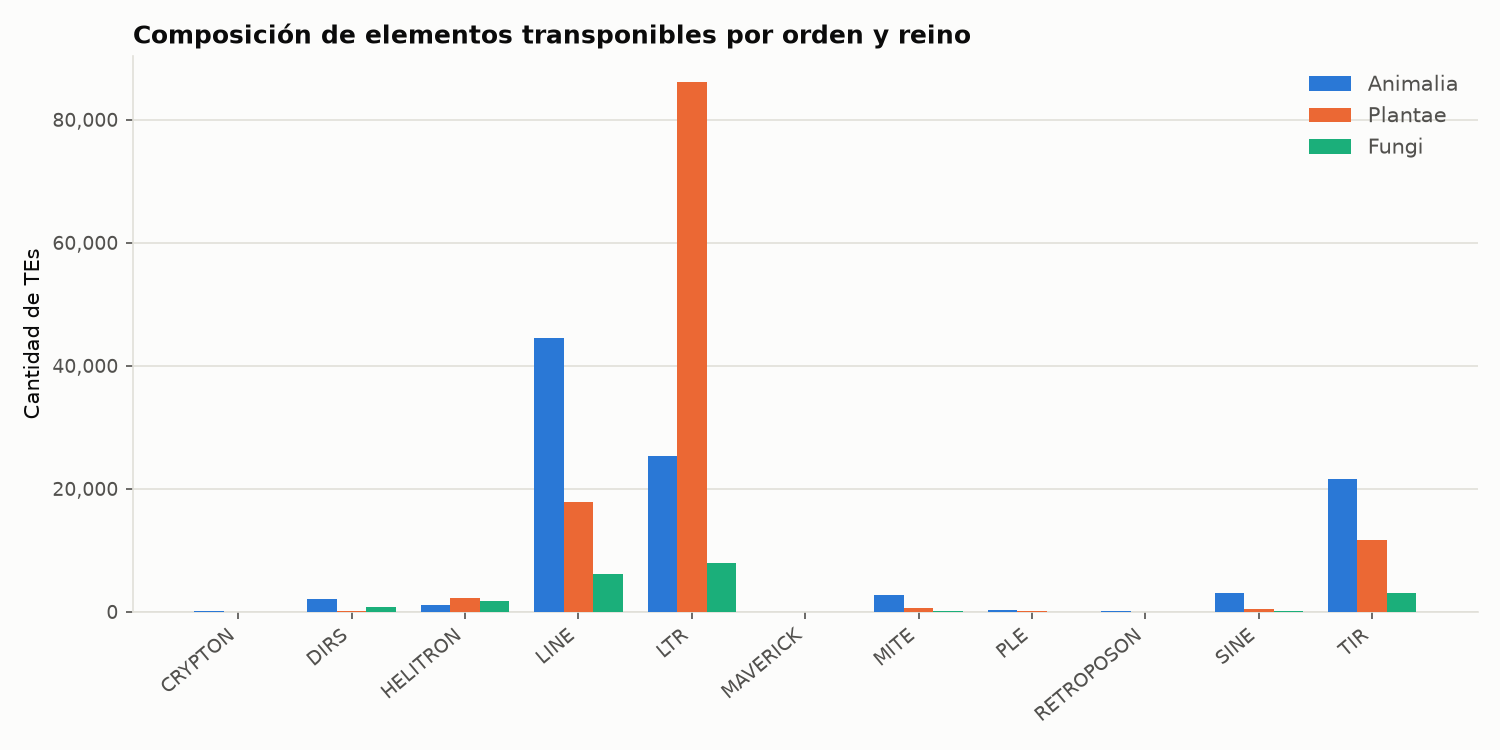

In [20]:
path = viz.fig1_composition_by_kingdom()
display(Image(filename=path))

**Interpretación:** LTR domina en Plantae (~86,000) mientras que LINE domina
en Animalia (~44,500) — el mismo patrón ya observado en la consulta 3, ahora
visible de un vistazo para los 11 órdenes y los 3 reinos a la vez.

### Figura 2 — Longitud de los TEs por orden (boxplot)

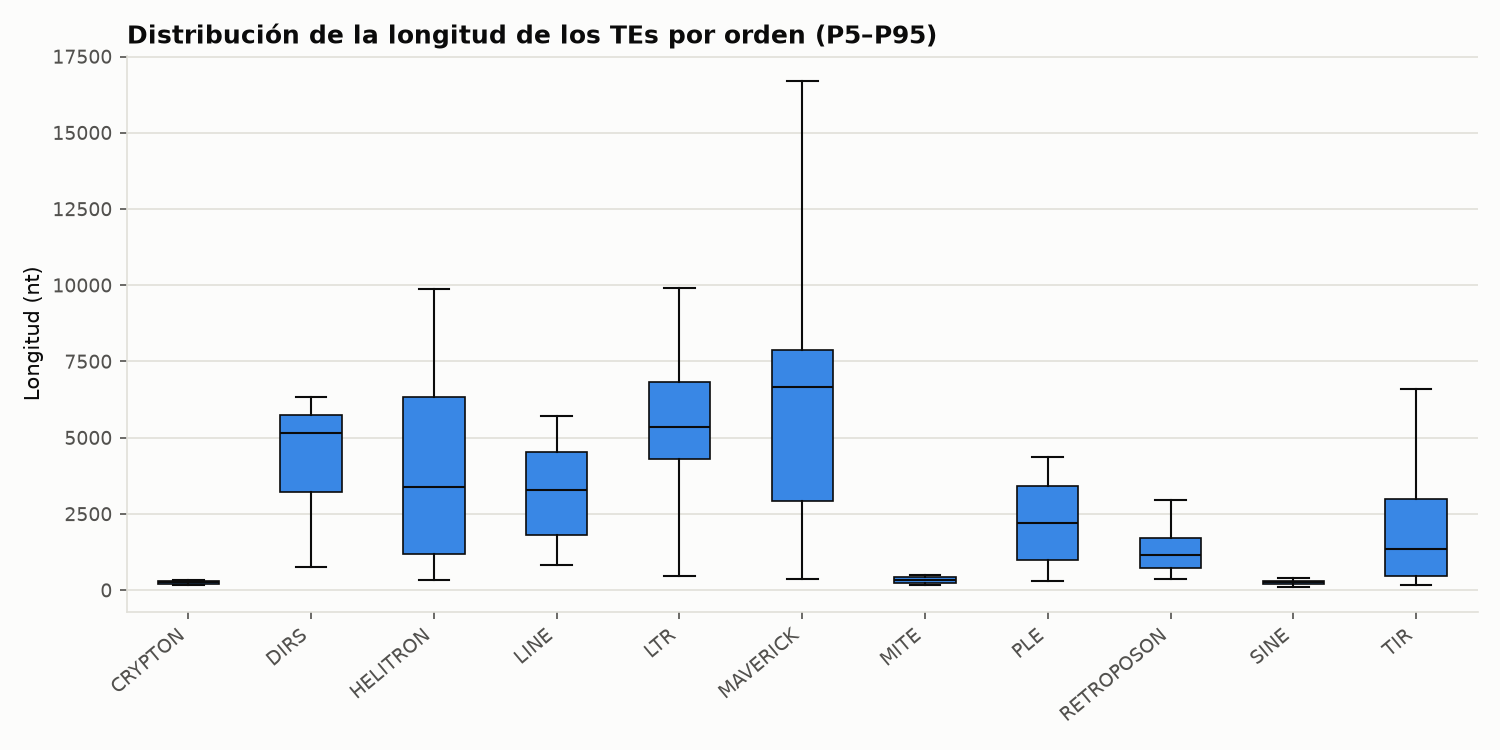

In [21]:
path = viz.fig2_length_boxplot_by_order()
display(Image(filename=path))

**Interpretación:** MAVERICK y LTR tienen las medianas de longitud más altas
y la dispersión más amplia; SINE y MITE son consistentemente cortos y con poca
dispersión — consistente con que SINE/MITE son elementos no autónomos muy
compactos, mientras que LTR/MAVERICK pueden incluir la maquinaria completa de
transposición.

### Figura 3 — Contenido GC por reino

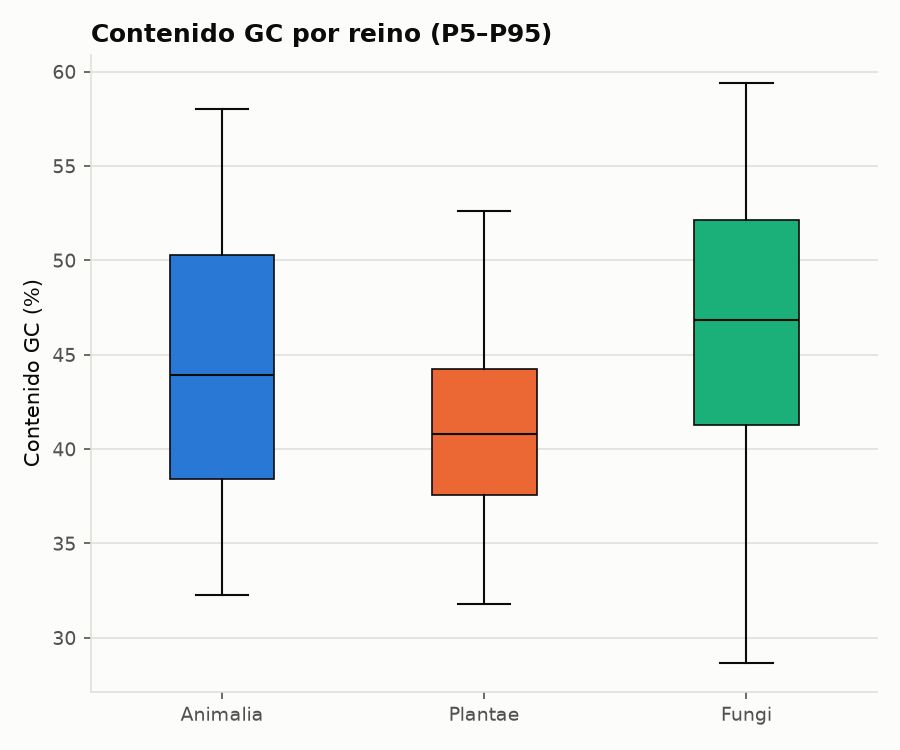

In [22]:
path = viz.fig3_gc_by_kingdom()
display(Image(filename=path))

**Interpretación:** Fungi tiene la mediana de GC% más alta y Plantae la más
baja, confirmando el patrón de la consulta 6; los rangos (P5–P95) se solapan
bastante entre los tres reinos, por lo que el GC% por sí solo no distingue
reinos de forma tajante a nivel de TE individual.

### Figura 4 — Heatmap de 2-mers por orden

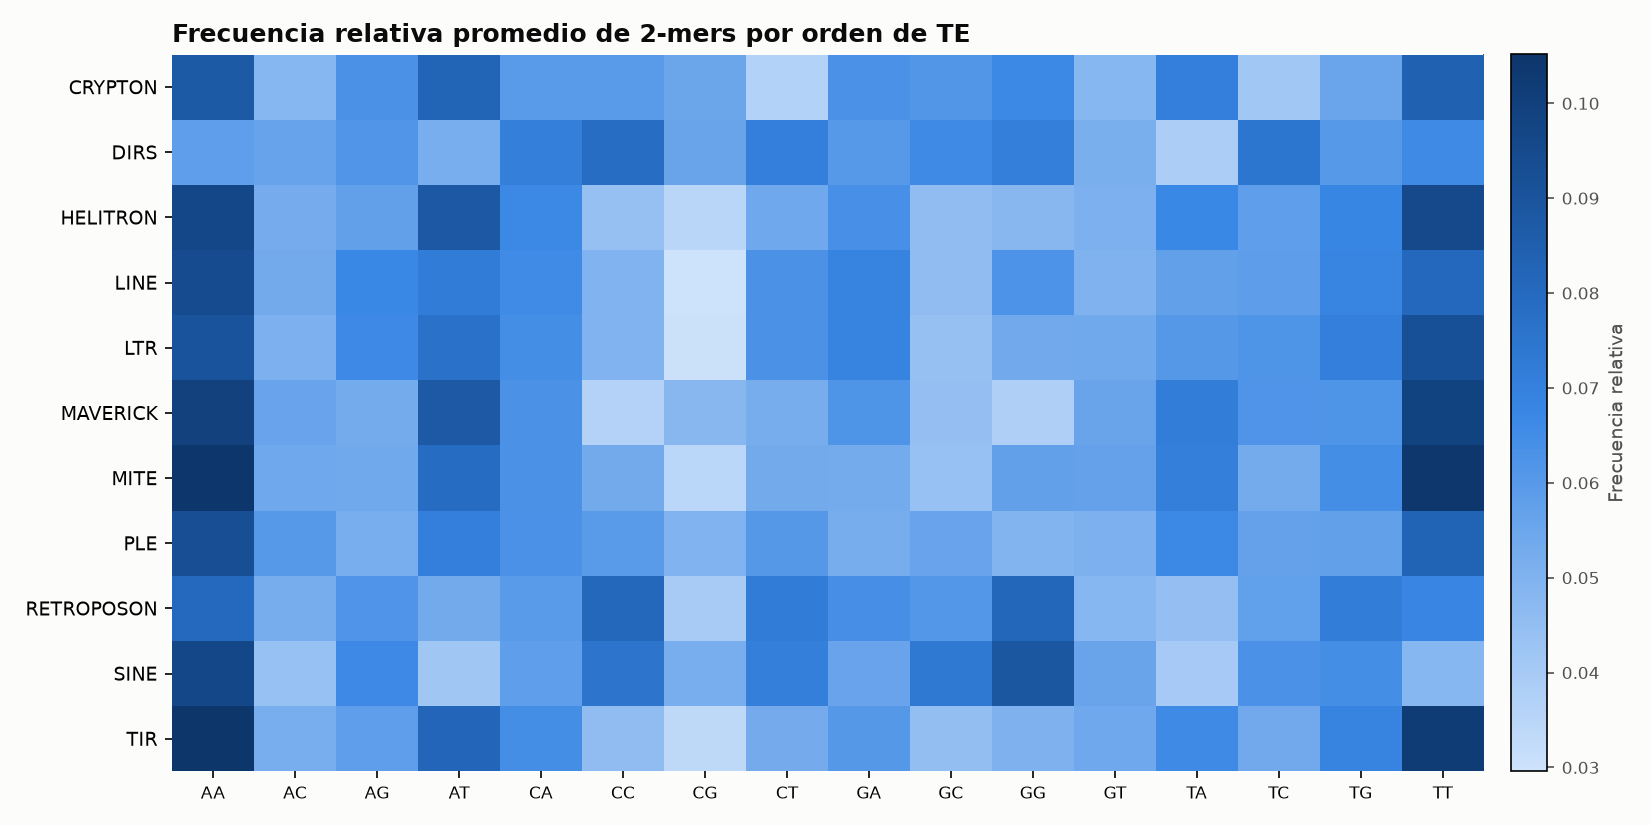

In [23]:
path = viz.fig4_heatmap_dinucleotide_by_order()
display(Image(filename=path))

**Interpretación:** casi todos los órdenes comparten el mismo patrón
dominante (AA/TT/AT altos, CG consistentemente el más bajo — el conocido
"CpG deficit" de los genomas eucariotas). RETROPOSON y SINE se distinguen del
resto por tener CC y GG relativamente más altos que los demás órdenes,
sugiriendo una composición de base ligeramente distinta en esas familias.